# DEMO canny_project: Canny Edge Detector từ toán học đến thực nghiệm

Notebook này đi theo đúng mạch của [Lab3.ipynb](../Lab3.ipynb) (Bài 1 → Bài 4) nhưng dùng gói `cannylab`:
Canny **tự cài đặt bằng NumPy** (`cannylab.core`, không dùng cv2/skimage), có ground truth để **chấm điểm** bằng
Precision / Recall / F1 thay vì chỉ nhìn bằng mắt.

| Phần | Nội dung | Mã yêu cầu |
|---|---|---|
| 0 | Từng bước của thuật toán | T1a |
| 1 | Canny tự cài so với OpenCV và scikit-image | P1 |
| 2 | Thay đổi tham số σ, ngưỡng thấp, ngưỡng cao | P2 |
| 3 | Ảnh khó: nhiễu, tương phản thấp, mờ, texture | P3, E2 |
| 4 | Phân đoạn và nhận dạng hình | P4 |
| 5 | Mở rộng: so với Sobel/LoG, ảnh màu, video, tốc độ | T1b, E3, E4, T3a |

**Chạy:** chọn kernel Python của `CV_Labs/.venv` rồi *Run All* (khoảng 1 phút).
Nếu chưa cài gói: `.venv/bin/pip install -e Lab3/canny_project` (ô dưới cũng tự thêm `src/` vào đường dẫn).

## Khai báo thư viện

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src" / "cannylab").exists() else Path.cwd() / "Lab3" / "canny_project"
try:
    import cannylab
except ImportError:                       # chưa pip install -e: dùng thẳng mã nguồn
    sys.path.insert(0, str(ROOT / "src"))
    import cannylab

import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data, feature
from scipy.ndimage import gaussian_filter1d

from cannylab.core import canny, OPENCV, SKIMAGE            # Canny tự cài (NumPy)
from cannylab.core.color import canny_color
from cannylab.datasets import synthetic as syn                # ảnh tổng hợp có ground truth
from cannylab.evaluation import edge_metrics                  # Precision / Recall / F1 có dung sai 1.5 px
from cannylab.analysis.segmentation import segment_by_edges
from cannylab.analysis.shapes import recognize_shapes
from cannylab import registry

plt.rcParams["figure.dpi"] = 90
print("cannylab", cannylab.__version__, "| OpenCV", cv2.__version__)

cannylab 1.0.0 | OpenCV 5.0.0


In [2]:
def show(images, titles, cols=None, size=3.0, cmaps=None):
    """Vẽ một hàng (hoặc lưới) ảnh, tắt trục. cmaps: list colormap từng ảnh (mặc định 'gray')."""
    cols = cols or len(images)
    rows = int(np.ceil(len(images) / cols))
    cmaps = cmaps or ["gray"] * len(images)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, t, cm in zip(axes.flat, images, titles, cmaps):
        ax.imshow(im, cmap=cm if np.ndim(im) == 2 else None)
        ax.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

def f1(edges, gt):
    return edge_metrics(edges, gt)["f1"]

# Bảng màu phân loại cố định (đã kiểm chứng an toàn cho người mù màu). Màu gắn với phương pháp, không theo thứ hạng.
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
INK, MUTED = "#333333", "#888888"

def style(ax, title=None, xlabel=None, ylabel=None, grid_axis="y"):
    """Trục và lưới nhạt, bỏ khung trên/phải."""
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    for sp in ("left", "bottom"):
        ax.spines[sp].set_color(MUTED)
    ax.tick_params(colors=INK, labelsize=9)
    ax.grid(axis=grid_axis, color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
    if title: ax.set_title(title, fontsize=11, color=INK, loc="left", pad=28)
    if xlabel: ax.set_xlabel(xlabel, color=INK)
    if ylabel: ax.set_ylabel(ylabel, color=INK)

def grouped_bars(ax, groups, series, values, horizontal=False, fmt="{:.2f}", label_best=True):
    """values[i][j] = nhóm i, chuỗi j. Khe trắng giữa các cột; chỉ ghi số trên cột cao nhất mỗi nhóm."""
    n = len(series); w = 0.8 / n; pos = np.arange(len(groups))
    draw = ax.barh if horizontal else ax.bar
    for j, name in enumerate(series):
        draw(pos - 0.4 + w * (j + 0.5), [values[i][j] for i in range(len(groups))], w,
             color=PAL[j], edgecolor="white", linewidth=1.5, label=name)
    if label_best:
        span = max(max(v) for v in values)
        for i in range(len(groups)):
            j = int(np.argmax(values[i])); x = pos[i] - 0.4 + w * (j + 0.5); v = values[i][j]
            if horizontal: ax.text(v + span * 0.01, x, fmt.format(v), va="center", fontsize=8, color=INK)
            else: ax.text(x, v + span * 0.01, fmt.format(v), ha="center", va="bottom", fontsize=8, color=INK)
    (ax.set_yticks if horizontal else ax.set_xticks)(pos, groups)
    if horizontal: ax.invert_yaxis()
    ax.legend(frameon=False, fontsize=9, ncol=min(n, 4), loc="lower left", bbox_to_anchor=(0, 1.0))

rng = np.random.default_rng(0)
scene = syn.shapes_scene(256, rng=rng)        # 6 hình: ảnh float [0,1] + ground truth cạnh + nhãn
GT = scene["edges"]
camera = data.camera()

## Phần 0. Canny từng bước

`canny()` trả về **mọi bước trung gian** (`CannyResult`), nên có thể nhìn tận mắt 5 bước của thuật toán:
1. Làm trơn Gauss (σ) → 2. Gradient Sobel (độ lớn, hướng) → 3. Non-maximum suppression (làm mảnh cạnh)
→ 4. Ngưỡng kép (mạnh / yếu) → 5. Hysteresis (giữ cạnh yếu nối với cạnh mạnh).

sigma = 2.0, ngưỡng hiệu dụng: thấp = 0.100, cao = 0.200


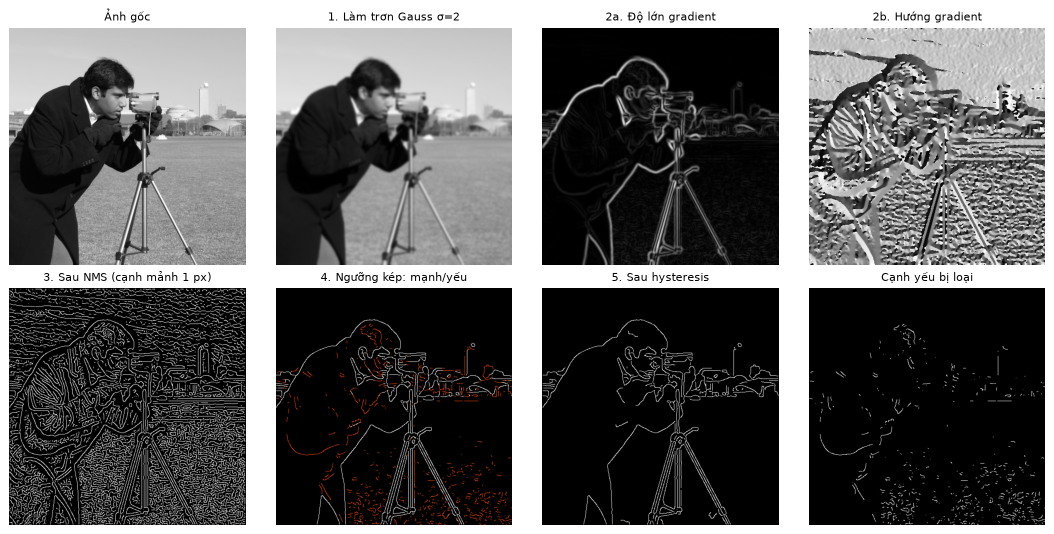

In [3]:
r = canny(camera, sigma=2.0, profile=SKIMAGE)   # hồ sơ skimage: ảnh về [0,1], ngưỡng mặc định 0.1 / 0.2
print(f"sigma = {r.sigma}, ngưỡng hiệu dụng: thấp = {r.low:.3f}, cao = {r.high:.3f}")

ws = np.zeros((*camera.shape, 3))
ws[r.strong] = (1, 1, 1)          # trắng: cạnh mạnh
ws[r.weak] = (1, 0.3, 0)          # cam:   cạnh yếu (chờ hysteresis quyết định)

show([camera, r.smoothed, r.magnitude, np.arctan2(r.gy, r.gx),
      r.nms > 0, ws, r.edges, r.candidate & ~r.edges],
     ["Ảnh gốc", "1. Làm trơn Gauss σ=2", "2a. Độ lớn gradient", "2b. Hướng gradient",
      "3. Sau NMS (cạnh mảnh 1 px)", "4. Ngưỡng kép: mạnh/yếu", "5. Sau hysteresis", "Cạnh yếu bị loại"],
     cols=4)

**Nhận xét:** sau NMS cạnh chỉ còn dày 1 pixel. Ngưỡng kép chia điểm cạnh thành mạnh (trắng) và yếu (cam);
hysteresis giữ lại những điểm yếu **nối được** với điểm mạnh và bỏ các điểm yếu lẻ loi (ô cuối), nhờ vậy
cạnh vừa liền mạch vừa ít nhiễu.

## Bài 1. Canny tự cài so với OpenCV và scikit-image

Bản tự cài có 2 "hồ sơ": `OPENCV` (tái tạo `cv2.Canny`: ảnh uint8, Sobel 3×3, NMS lượng tử 4 hướng) và
`SKIMAGE` (tái tạo `skimage.feature.canny`: Gauss σ, NMS nội suy song tuyến). Kiểm chứng bằng cách
**đếm số pixel lệch** (XOR) trên các ảnh thật của `skimage.data`.

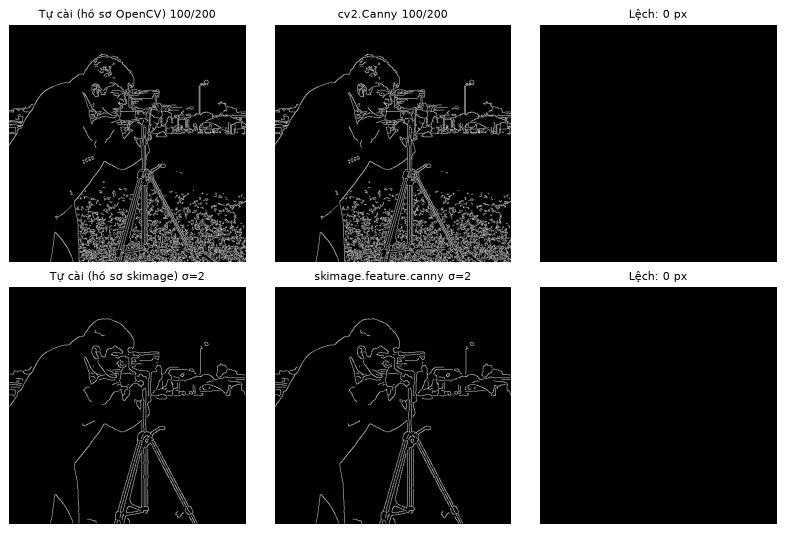

In [4]:
ours_cv = canny(camera, None, 100, 200, profile=OPENCV).edges
ref_cv = cv2.Canny(camera, 100, 200) > 0
ours_sk = canny(camera, 2.0, profile=SKIMAGE).edges
ref_sk = feature.canny(camera, sigma=2.0)

show([ours_cv, ref_cv, ours_cv ^ ref_cv, ours_sk, ref_sk, ours_sk ^ ref_sk],
     ["Tự cài (hồ sơ OpenCV) 100/200", "cv2.Canny 100/200", f"Lệch: {(ours_cv ^ ref_cv).sum()} px",
      "Tự cài (hồ sơ skimage) σ=2", "skimage.feature.canny σ=2", f"Lệch: {(ours_sk ^ ref_sk).sum()} px"], cols=3)

In [5]:
print(f"{'Ảnh':8s} {'cv2 100/200':>12s} {'cv2 50/150 L2':>14s} {'skimage σ=1':>12s} {'skimage σ=2':>12s}   (số pixel lệch)")
names_b1, counts_b1 = ["camera", "coins", "moon", "page", "text", "brick"], []
for name in names_b1:
    img = getattr(data, name)()
    counts_b1.append([int(canny(img, None, 100, 200, profile=OPENCV).edges.sum()), int((cv2.Canny(img, 100, 200) > 0).sum()),
                      int(canny(img, 2.0, profile=SKIMAGE).edges.sum()), int(feature.canny(img, sigma=2.0).sum())])
    d = [(canny(img, None, 100, 200, profile=OPENCV).edges ^ (cv2.Canny(img, 100, 200) > 0)).sum(),
         (canny(img, None, 50, 150, profile=OPENCV, norm="L2").edges ^ (cv2.Canny(img, 50, 150, L2gradient=True) > 0)).sum()]
    d += [(canny(img, s, profile=SKIMAGE).edges ^ feature.canny(img, sigma=s)).sum() for s in (1.0, 2.0)]
    print(f"{name:8s}" + "".join(f"{v:>13d}" for v in d))

Ảnh       cv2 100/200  cv2 50/150 L2  skimage σ=1  skimage σ=2   (số pixel lệch)


camera              0            0            0            0
coins               0            0            0            0


moon                0            0            0            0
page                0            0            0            0


text                0            0            0            0


brick               0            0            0            0


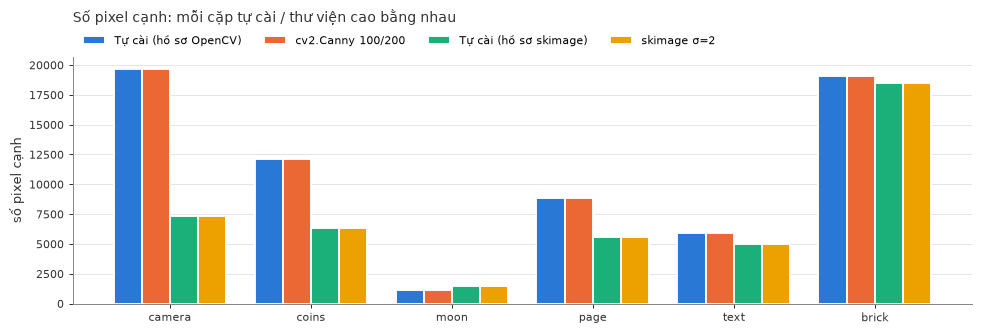

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.8))
grouped_bars(ax, names_b1, ["Tự cài (hồ sơ OpenCV)", "cv2.Canny 100/200", "Tự cài (hồ sơ skimage)", "skimage σ=2"],
             counts_b1, label_best=False)
style(ax, "Số pixel cạnh: mỗi cặp tự cài / thư viện cao bằng nhau", ylabel="số pixel cạnh")
plt.tight_layout(); plt.show()

**Nhận xét:** bản tự cài **trùng tuyệt đối** với cả hai thư viện (0 pixel lệch). Như vậy mọi thực nghiệm phía sau
chạy trên bản tự cài đều có giá trị như chạy trên thư viện, và ta hiểu được từng con số bên trong.
(Kiểm chứng đầy đủ 6 ảnh × 12 cấu hình: `python -m cannylab verify`, thực nghiệm X1.)

## Bài 2. Thay đổi tham số và quan sát kết quả

Khác Lab3: dùng ảnh tổng hợp **có ground truth** (6 hình, thêm nhiễu Gauss σ_n = 0.05) để chấm F1, không chỉ
đếm tỉ lệ pixel cạnh. F1 = trung bình điều hòa của Precision (bao nhiêu cạnh tìm được là đúng) và Recall
(tìm được bao nhiêu cạnh thật), dung sai 1.5 px.

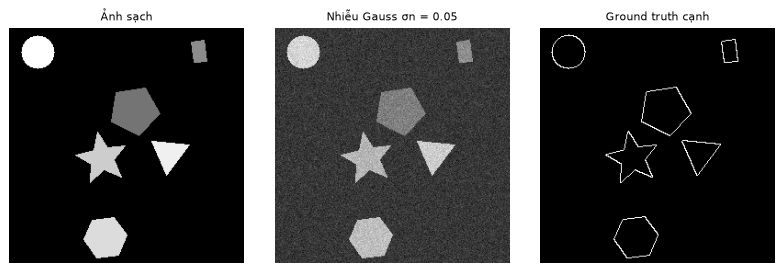

In [7]:
noisy = syn.degrade(scene["image"], np.random.default_rng(1), noise_sigma=0.05)
show([scene["image"], noisy, GT], ["Ảnh sạch", "Nhiễu Gauss σn = 0.05", "Ground truth cạnh"])

### 2.1. Thay đổi σ (giữ ngưỡng 0.1 / 0.2)

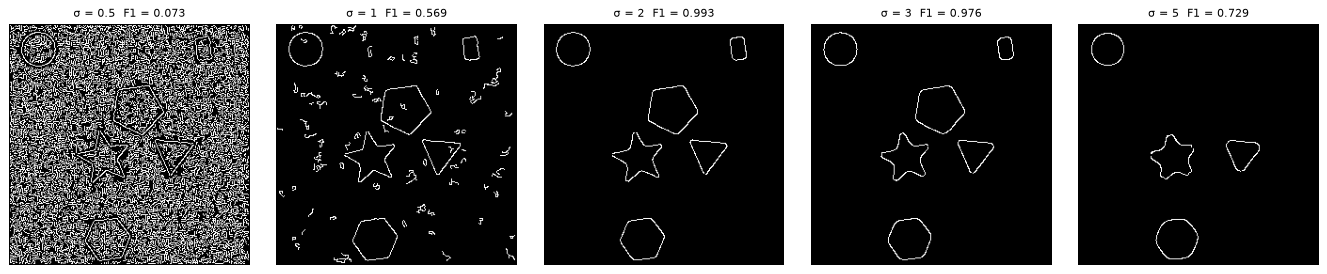

σ = 0.5  P = 0.038  R = 1.000  F1 = 0.073   max|∇| = 2.571
σ = 1    P = 0.398  R = 0.999  F1 = 0.569   max|∇| = 1.642
σ = 2    P = 0.999  R = 0.988  F1 = 0.993   max|∇| = 0.897
σ = 3    P = 0.993  R = 0.959  F1 = 0.976   max|∇| = 0.602
σ = 5    P = 0.948  R = 0.592  F1 = 0.729   max|∇| = 0.358


In [8]:
sigmas = [0.5, 1, 2, 3, 5]
res = [canny(noisy, s, 0.1, 0.2) for s in sigmas]
show([x.edges for x in res], [f"σ = {s}  F1 = {f1(x.edges, GT):.3f}" for s, x in zip(sigmas, res)])
for s, x in zip(sigmas, res):
    m = edge_metrics(x.edges, GT)
    print(f"σ = {s:<4} P = {m['precision']:.3f}  R = {m['recall']:.3f}  F1 = {m['f1']:.3f}   max|∇| = {x.magnitude.max():.3f}")

### 2.2. Thay đổi ngưỡng cao (σ = 1, ngưỡng thấp 0.05)

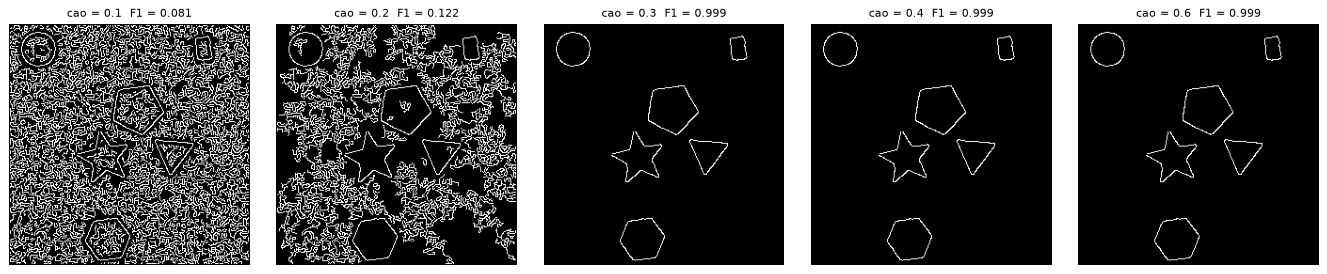

In [9]:
highs = [0.1, 0.2, 0.3, 0.4, 0.6]
eh = [canny(noisy, 1.0, 0.05, hi).edges for hi in highs]
show(eh, [f"cao = {hi}  F1 = {f1(e, GT):.3f}" for hi, e in zip(highs, eh)])

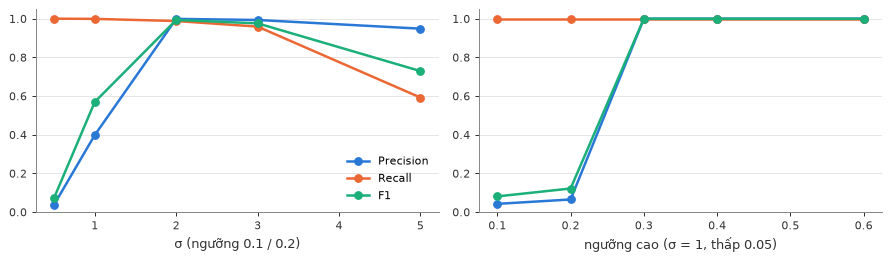

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, xs, es, lab in [(ax[0], sigmas, [x.edges for x in res], "σ (ngưỡng 0.1 / 0.2)"),
                       (ax[1], highs, eh, "ngưỡng cao (σ = 1, thấp 0.05)")]:
    ms = [edge_metrics(e, GT) for e in es]
    for c, k, name in zip(PAL, ("precision", "recall", "f1"), ("Precision", "Recall", "F1")):
        a.plot(xs, [m[k] for m in ms], "o-", color=c, lw=2, ms=6, label=name)
    a.set_ylim(0, 1.05); style(a, xlabel=lab)
ax[0].legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

### 2.2b. Histogram độ lớn gradient: vì sao phải chọn ngưỡng theo σ
Histogram các giá trị **sau NMS** (chỉ các cực đại địa phương, ứng viên cạnh), tách thành 2 nhóm bằng ground truth:
điểm thuộc **cạnh thật** và điểm do **nhiễu**. Ngưỡng tốt là ngưỡng nằm giữa hai "đồi" này.
Vạch nét liền là ngưỡng cố định 0.1 / 0.2, vạch nét đứt là ngưỡng do chiến lược `noise` tự chọn.

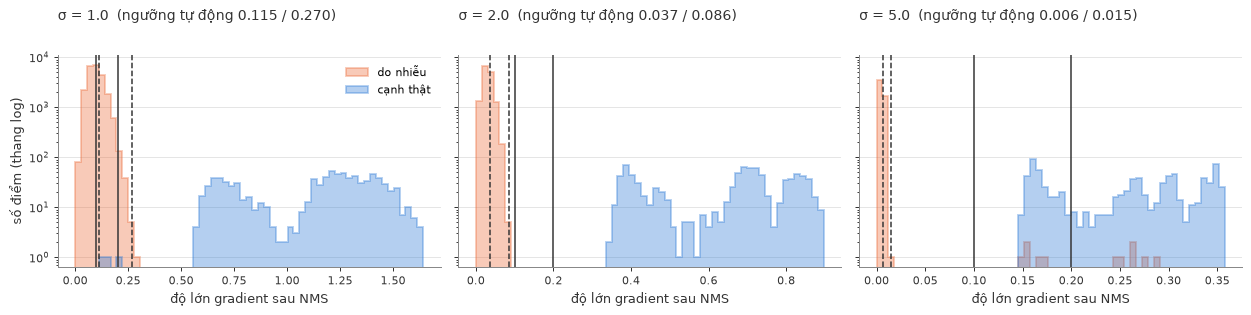

In [11]:
from scipy.ndimage import binary_dilation
near_gt = binary_dilation(GT, iterations=2)     # vùng ±2 px quanh cạnh thật

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, s in zip(axes, [1.0, 2.0, 5.0]):
    r_fix = canny(noisy, s, 0.1, 0.2)
    r_auto = canny(noisy, s, threshold_strategy="noise")
    v = r_fix.nms
    bins = np.linspace(0, v.max(), 60)
    ax.hist(v[(v > 0) & ~near_gt], bins, histtype="stepfilled", color=PAL[1], alpha=0.35, ec=PAL[1], lw=1.5,
            label="do nhiễu")
    ax.hist(v[(v > 0) & near_gt], bins, histtype="stepfilled", color=PAL[0], alpha=0.35, ec=PAL[0], lw=1.5,
            label="cạnh thật")
    for x in (r_fix.low, r_fix.high):
        ax.axvline(x, color=INK, lw=1.2)
    for x in (r_auto.low, r_auto.high):
        ax.axvline(x, color=INK, lw=1.2, ls="--")
    ax.set_yscale("log")
    style(ax, f"σ = {s}  (ngưỡng tự động {r_auto.low:.3f} / {r_auto.high:.3f})", xlabel="độ lớn gradient sau NMS")
axes[0].set_ylabel("số điểm (thang log)", color=INK)
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

**Đọc histogram:** σ nhỏ thì đồi nhiễu (cam) trải rộng, vượt qua ngưỡng cố định 0.1 / 0.2 nên lọt nhiều cạnh giả.
σ lớn thì nhiễu bị nén về gần 0, **nhưng đồi cạnh thật cũng dịch sang trái** (đỉnh gradient ∝ 1/σ), đến σ = 5 một phần
cạnh thật rơi xuống dưới ngưỡng cao cố định nên bị mất. Ngưỡng tự động (nét đứt) đi theo σ, luôn nằm ngay trên đồi nhiễu.

### 2.3. Thay đổi ngưỡng thấp (ảnh thật `camera`, σ = 2, ngưỡng cao 0.2)
Ảnh tổng hợp có tương phản cao nên ngưỡng thấp gần như không đổi F1 (mọi điểm cạnh thật đều vượt ngưỡng cao).
Tác dụng của ngưỡng thấp thấy rõ trên ảnh thật có nhiều cạnh yếu: nó quyết định cạnh **nối dài** tới đâu.

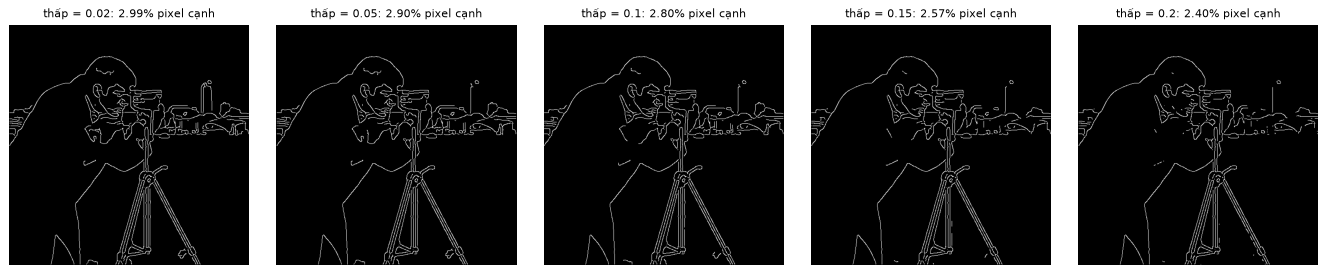

In [12]:
lows = [0.02, 0.05, 0.1, 0.15, 0.2]
cam_f = camera / 255.0   # ảnh uint8 thì ngưỡng cố định tính theo thang 0..255 (như skimage), nên đưa về [0, 1]
el = [canny(cam_f, 2.0, lo, 0.2).edges for lo in lows]
show(el, [f"thấp = {lo}: {100 * e.mean():.2f}% pixel cạnh" for lo, e in zip(lows, el)])

**Nhận xét bài 2:**
- **σ** quyết định chống nhiễu: σ = 0.5–1 để lọt nhiễu (Precision thấp, F1 0.07–0.57), σ = 2 tốt nhất (F1 ≈ 0.99).
  σ quá lớn (5) lại **mất cạnh** (Recall 0.59), vì đỉnh gradient của một cạnh bậc thang giảm theo 1/σ
  (cột max|∇|: 2.57 → 0.36) trong khi ngưỡng giữ nguyên. Vậy đổi σ thì phải đổi ngưỡng theo.
- **Ngưỡng cao** quyết định điểm nào được làm "hạt giống": thấp quá thì nhiễu thành hạt giống (F1 0.08 khi = 0.1),
  từ 0.3 trở lên thì sạch (F1 ≈ 0.999). Ảnh này tương phản cao nên 0.6 vẫn chưa mất cạnh; với ảnh tương phản thấp,
  ngưỡng cao quá sẽ làm mất cả vật.
- **Ngưỡng thấp** quyết định cạnh nối dài đến đâu: thấp (0.02) thì cạnh liền mạch (2.99% pixel cạnh), cao (0.2) thì
  cạnh đứt đoạn (2.40%), thấy rõ ở chân máy ảnh và dãy nhà phía sau. Ngưỡng thấp không tạo thêm cạnh mới, vì điểm yếu
  chỉ được giữ khi nối được với một điểm mạnh. Thực nghiệm X2 quét đầy đủ trên 6 ảnh × 3 mức nhiễu.

## Bài 3. Ảnh khó

Cùng một cảnh, suy giảm theo 6 kiểu. So sánh **tham số mặc định** (σ = 1, ngưỡng 0.1/0.2) với 3 cách tự động:
- `threshold_strategy="noise"`: ước lượng σ nhiễu của ảnh rồi đặt ngưỡng trên mức gradient mà nhiễu có thể tạo ra;
- lọc trung vị 3×3 rồi ngưỡng Otsu (sau trung vị nhiễu không còn là Gauss nên không dùng "noise" được nữa);
- ngưỡng theo phân vị của độ lớn gradient (88% / 95%).

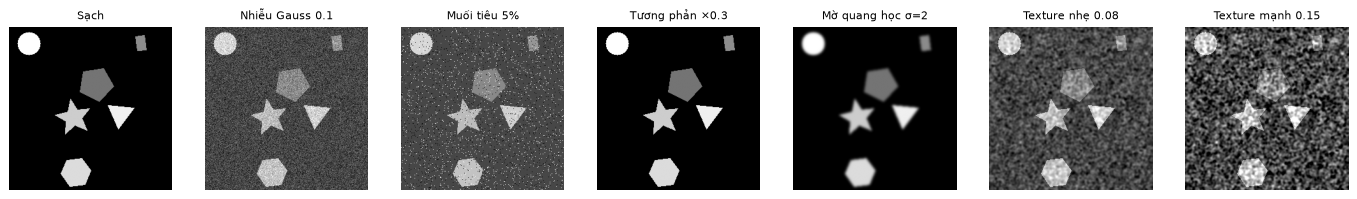

In [13]:
cases = {
    "Sạch": {},
    "Nhiễu Gauss 0.1": {"noise_sigma": 0.1},
    "Muối tiêu 5%": {"salt_pepper": 0.05},
    "Tương phản ×0.3": {"contrast": 0.3},
    "Mờ quang học σ=2": {"blur": 2.0},
    "Texture nhẹ 0.08": {"texture": 0.08},
    "Texture mạnh 0.15": {"texture": 0.15},
}
hard = {k: syn.degrade(scene["image"], np.random.default_rng(2), **v) for k, v in cases.items()}
show(list(hard.values()), list(hard.keys()), cols=7, size=2.2)

In [14]:
from cannylab.core.denoise import median_filter

methods = {
    "mặc định σ=1":        lambda im: canny(im, 1.0, 0.1, 0.2).edges,
    "σ=2 ngưỡng nhiễu":    lambda im: canny(im, 2.0, threshold_strategy="noise").edges,
    "trung vị 3×3 + Otsu":  lambda im: canny(median_filter(im, 3), 1.0, threshold_strategy="otsu").edges,
    "σ=2 phân vị 88/95%":   lambda im: canny(im, 2.0, threshold_strategy="quantile",
                                           strategy_params=dict(low_q=0.88, high_q=0.95)).edges,
}
out = {(c, m): fn(im) for c, im in hard.items() for m, fn in methods.items()}

print(f"{'Ảnh':18s}" + "".join(f"{m:>22s}" for m in methods) + "   (F1)")
for c in hard:
    print(f"{c:18s}" + "".join(f"{f1(out[c, m], GT):>22.3f}" for m in methods))

Ảnh                         mặc định σ=1      σ=2 ngưỡng nhiễu   trung vị 3×3 + Otsu    σ=2 phân vị 88/95%   (F1)
Sạch                               1.000                 0.992                 0.998                 0.992
Nhiễu Gauss 0.1                    0.081                 0.971                 0.998                 0.992
Muối tiêu 5%                       0.141                 0.131                 0.998                 0.992
Tương phản ×0.3                    1.000                 0.992                 0.998                 0.992
Mờ quang học σ=2                   0.990                 0.979                 0.988                 0.865
Texture nhẹ 0.08                   0.104                 0.123                 0.938                 0.875
Texture mạnh 0.15                  0.101                 0.111                 0.129                 0.477


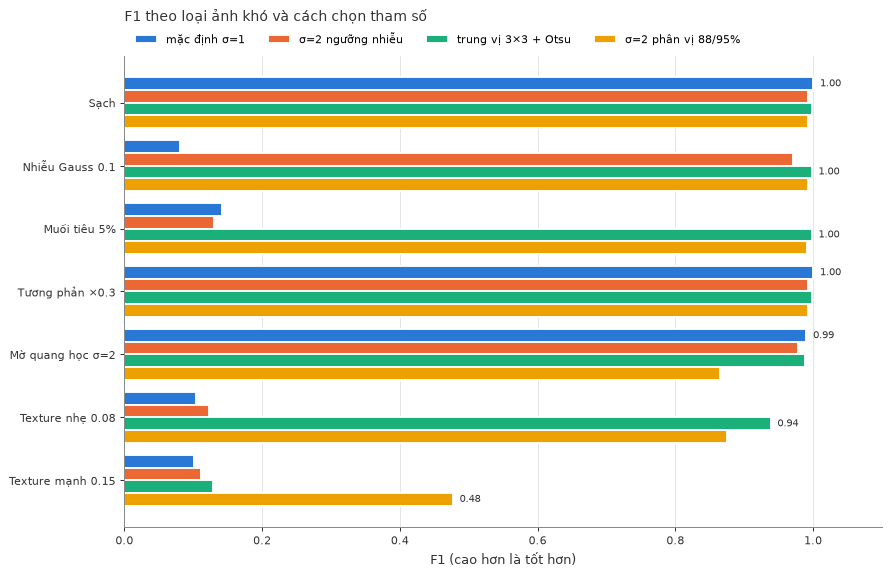

In [15]:
fig, ax = plt.subplots(figsize=(10, 6.5))
grouped_bars(ax, list(hard), list(methods), [[f1(out[c, m], GT) for m in methods] for c in hard], horizontal=True)
ax.set_xlim(0, 1.1)
style(ax, "F1 theo loại ảnh khó và cách chọn tham số", xlabel="F1 (cao hơn là tốt hơn)", grid_axis="x")
plt.tight_layout(); plt.show()

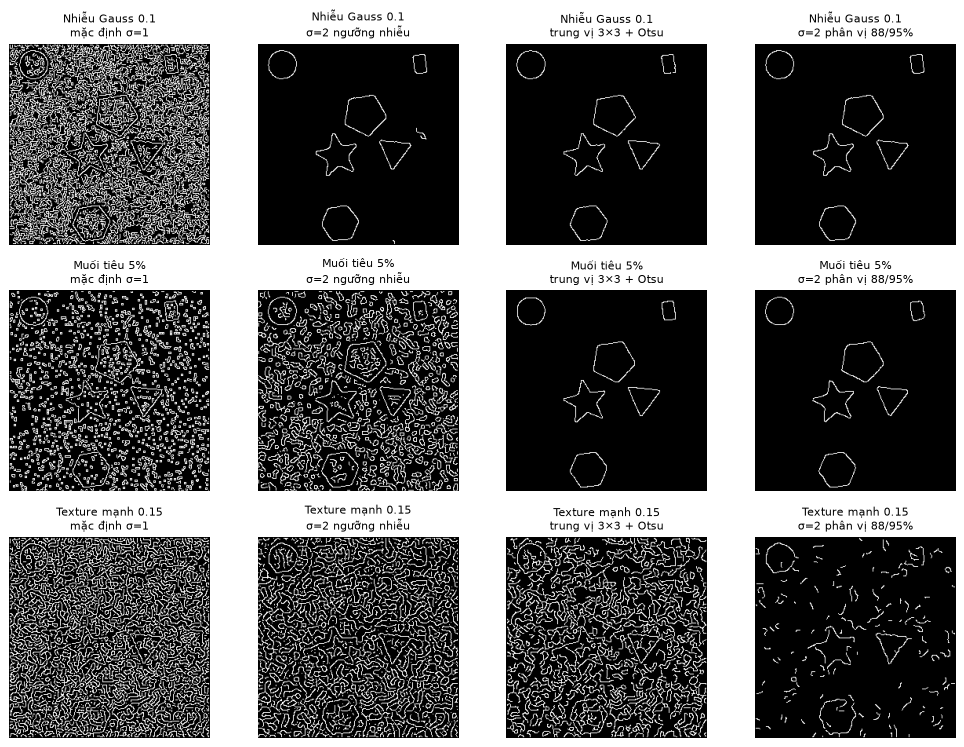

In [16]:
rows = ["Nhiễu Gauss 0.1", "Muối tiêu 5%", "Texture mạnh 0.15"]
show([out[c, m] for c in rows for m in methods], [f"{c}\n{m}" for c in rows for m in methods], cols=4, size=2.8)

### 3.3. Histogram: ảnh khó khác ảnh sạch ở đâu
Hàng trên: histogram **cường độ sáng** của ảnh. Hàng dưới: histogram **độ lớn gradient sau NMS** (σ = 1), chia cạnh
thật / nhiễu như mục 2.2b, kèm ngưỡng mặc định 0.1 / 0.2 (nét liền).

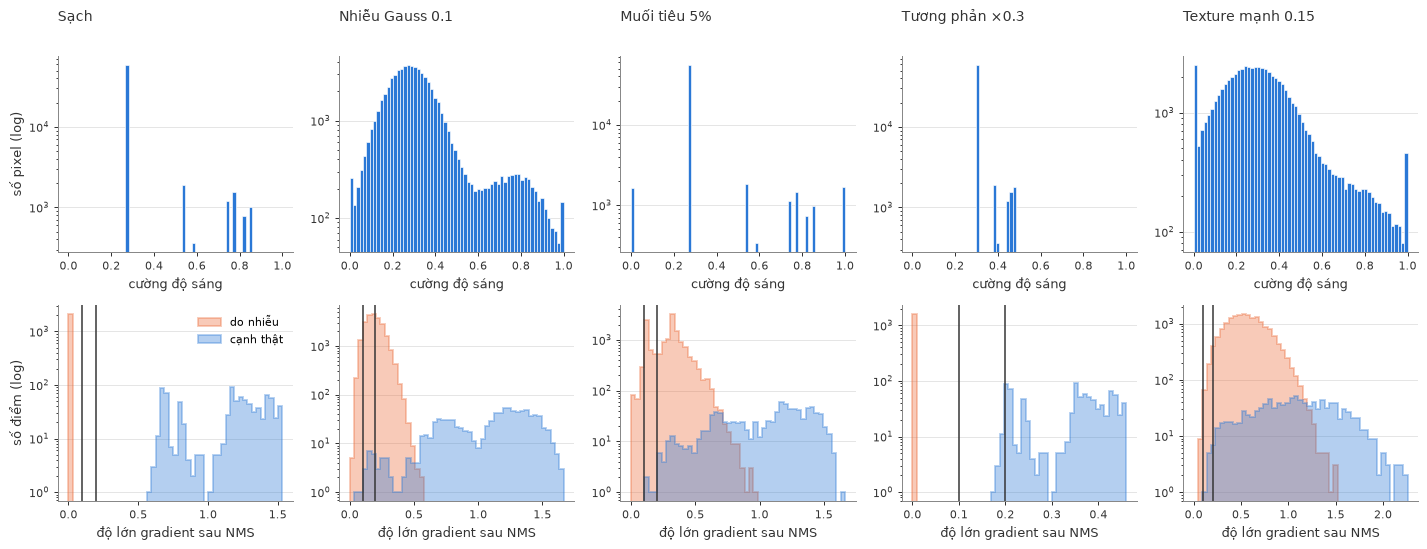

In [17]:
show_cases = ["Sạch", "Nhiễu Gauss 0.1", "Muối tiêu 5%", "Tương phản ×0.3", "Texture mạnh 0.15"]
fig, axes = plt.subplots(2, len(show_cases), figsize=(16, 6.2))
for k, c in enumerate(show_cases):
    im = hard[c]
    ax = axes[0, k]
    ax.hist(im.ravel(), np.linspace(0, 1, 65), color=PAL[0], ec="white", lw=0.5)
    ax.set_yscale("log"); style(ax, c, xlabel="cường độ sáng")
    ax = axes[1, k]
    r_c = canny(im, 1.0, 0.1, 0.2); v = r_c.nms
    bins = np.linspace(0, max(v.max(), 0.25), 50)
    ax.hist(v[(v > 0) & ~near_gt], bins, histtype="stepfilled", color=PAL[1], alpha=0.35, ec=PAL[1], lw=1.5, label="do nhiễu")
    ax.hist(v[(v > 0) & near_gt], bins, histtype="stepfilled", color=PAL[0], alpha=0.35, ec=PAL[0], lw=1.5, label="cạnh thật")
    for x in (r_c.low, r_c.high):
        ax.axvline(x, color=INK, lw=1.2)
    ax.set_yscale("log"); style(ax, xlabel="độ lớn gradient sau NMS")
axes[0, 0].set_ylabel("số pixel (log)", color=INK); axes[1, 0].set_ylabel("số điểm (log)", color=INK)
axes[1, 0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

**Đọc histogram:**
- **Sạch / tương phản thấp:** histogram cường độ chỉ có vài vạch (mỗi vật một mức xám), gradient chỉ có đồi cạnh thật.
  Tương phản ×0.3 dồn các vạch lại gần nhau và kéo đồi cạnh sang trái: một phần cạnh rơi xuống dưới ngưỡng cao 0.2
  nhưng vẫn trên ngưỡng thấp 0.1, nên được hysteresis nối lại nhờ phần còn lại trên ngưỡng cao.
- **Nhiễu Gauss:** các vạch cường độ nhòe thành những quả chuông; đồi nhiễu ở gradient lấn qua cả hai ngưỡng.
- **Muối tiêu:** histogram cường độ có hai cột ở đúng 0 và 1; điểm xung tạo gradient **rất lớn**, nằm chung chỗ với cạnh
  thật, nên nâng ngưỡng không cứu được. Phải xóa xung bằng lọc trung vị trước.
- **Texture:** đồi "nhiễu" và đồi cạnh thật chồng lên nhau hoàn toàn: không ngưỡng nào tách được, đúng như F1 ở bảng trên.

**Đánh giá bài 3:**
- **Tham số mặc định** chỉ ổn với ảnh sạch, tương phản thấp và mờ; gặp nhiễu Gauss, muối tiêu hay texture thì F1 ≤ 0.14
  (ảnh đầy cạnh giả). Riêng tương phản ×0.3 vẫn đạt vì ảnh tổng hợp gốc có tương phản cao.
- **Ngưỡng theo nhiễu** cứu được nhiễu Gauss (0.08 → 0.97) nhưng **không** cứu được muối tiêu: nhiễu xung không phải Gauss,
  ước lượng σ nhiễu sai.
- **Trung vị 3×3 + Otsu** xử lý tốt cả nhiễu Gauss lẫn muối tiêu (0.998): trung vị xóa điểm xung mà giữ nguyên cạnh bậc thang.
- **Texture** khó nhất: texture cũng là "cạnh thật" về mặt gradient. Texture nhẹ còn cứu được (0.94), texture mạnh thì
  mọi cách đều thấp (≤ 0.48). Cần thông tin vùng/tỉ lệ, vượt quá khả năng của một bộ dò cạnh cục bộ.
- Không có một bộ tham số cho mọi ảnh: phải chọn theo loại suy giảm (thực nghiệm X3, X6).

## Bài 4. Kết hợp Canny với các kỹ thuật khác

### 4.1. Phân đoạn: Canny → closing → lấp lỗ → gán nhãn (tự cài trong `core.morphology`)

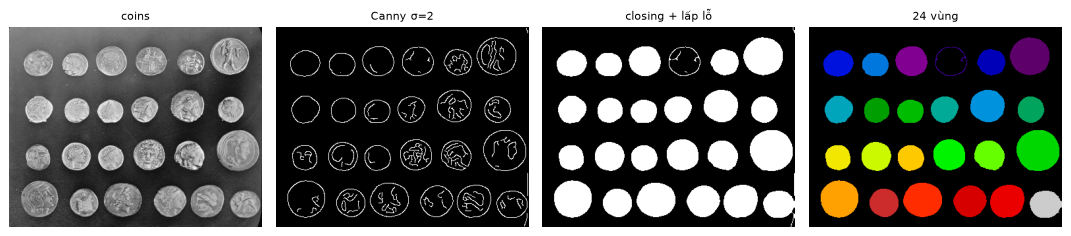

In [18]:
coins = data.coins()
e_coins = canny(coins, 2.0, profile=SKIMAGE).edges
seg_c = segment_by_edges(e_coins, close_size=5, min_area=150)
show([coins, e_coins, seg_c.filled, seg_c.labels],
     ["coins", "Canny σ=2", "closing + lấp lỗ", f"{seg_c.count} vùng"],
     cmaps=["gray", "gray", "gray", "nipy_spectral"])

### 4.2. Nhận dạng hình: dò biên → xấp xỉ đa giác (Douglas–Peucker) → đếm đỉnh, độ tròn, độ đặc

Khớp vùng với ground truth: {'object_precision': 1.0, 'object_recall': 1.0, 'object_f1': 1.0, 'mean_iou_matched': 0.9287053153507702, 'n_gt_objects': 6, 'n_pred_objects': 6, 'count_error': 0}


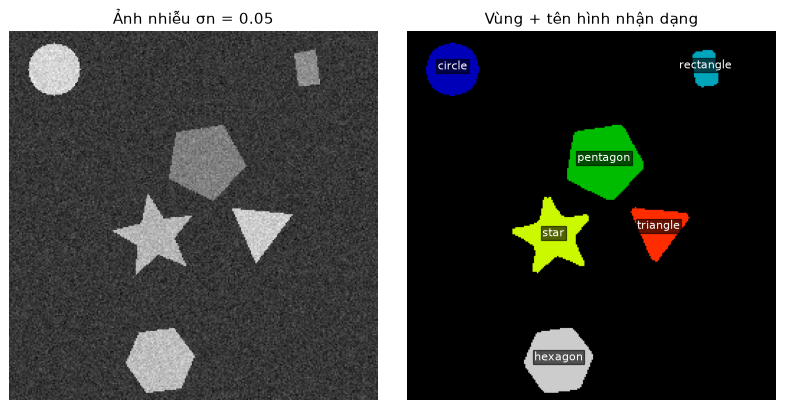

Ground truth: ['circle', 'hexagon', 'pentagon', 'rectangle', 'star', 'triangle']
Nhận dạng  : ['circle', 'hexagon', 'pentagon', 'rectangle', 'star', 'triangle']


In [19]:
from cannylab.evaluation import match_objects

seg = segment_by_edges(canny(noisy, 2.0, threshold_strategy="noise").edges)
found = recognize_shapes(seg.labels, seg.count)
match = match_objects(seg.labels, scene["labels"])
print("Khớp vùng với ground truth:", {k: match[k] for k in match if not isinstance(match[k], (list, dict))})

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].imshow(noisy, cmap="gray"); ax[0].set_title("Ảnh nhiễu σn = 0.05")
ax[1].imshow(seg.labels, cmap="nipy_spectral"); ax[1].set_title("Vùng + tên hình nhận dạng")
for f in found:
    ys, xs = np.nonzero(seg.labels == f["label"])
    ax[1].text(xs.mean(), ys.mean(), f["shape"], color="white", ha="center", fontsize=9,
               bbox=dict(facecolor="black", alpha=.6, pad=1))
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print("Ground truth:", sorted(scene["classes"].values()))
print("Nhận dạng  :", sorted(f["shape"] for f in found))

**Nhận xét bài 4:**
- Trên `coins`, Canny + closing + lấp lỗ tách được **24/24 đồng xu** (giống Lab3), nhưng bằng hình thái học tự cài.
- Trên ảnh tổng hợp có nhiễu, 6/6 vùng khớp ground truth (IoU trung bình ≈ 0.93) và **6/6 hình nhận dạng đúng**.
  IoU < 1 vì làm trơn σ = 2 bo tròn góc nhọn (rõ ở ngôi sao). Thực nghiệm X5: 60/60 vật, 100% nhận dạng trên ảnh sạch.

## Phần 5. Mở rộng

### 5.1. So với Sobel + ngưỡng và LoG (Marr–Hildreth)

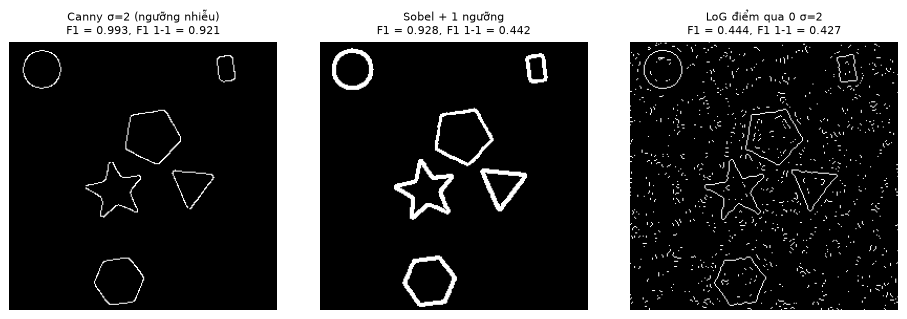

In [20]:
base = {"Canny σ=2 (ngưỡng nhiễu)": canny(noisy, 2.0, threshold_strategy="noise").edges,
        "Sobel + 1 ngưỡng": registry.run("sobel_threshold_manual", noisy, threshold=0.3, sigma=1.0),
        "LoG điểm qua 0 σ=2": registry.run("log_manual", noisy, sigma=2.0)}
show(list(base.values()), [f"{k}\nF1 = {f1(v, GT):.3f}, F1 1-1 = {edge_metrics(v, GT)['f1_1to1']:.3f}"
                           for k, v in base.items()], size=3.5)

F1 *một-một* ghép mỗi pixel ground truth với tối đa một pixel dự đoán, nên phạt cạnh dày (Sobel không có NMS,
cạnh dày 2–3 px). Canny vừa mảnh vừa liền.

Biểu đồ dưới: (trái) 4 chỉ số trên ảnh trên; (phải) F1 một-một khi **tăng dần mức nhiễu**, mỗi mức chạy trên cùng cảnh.

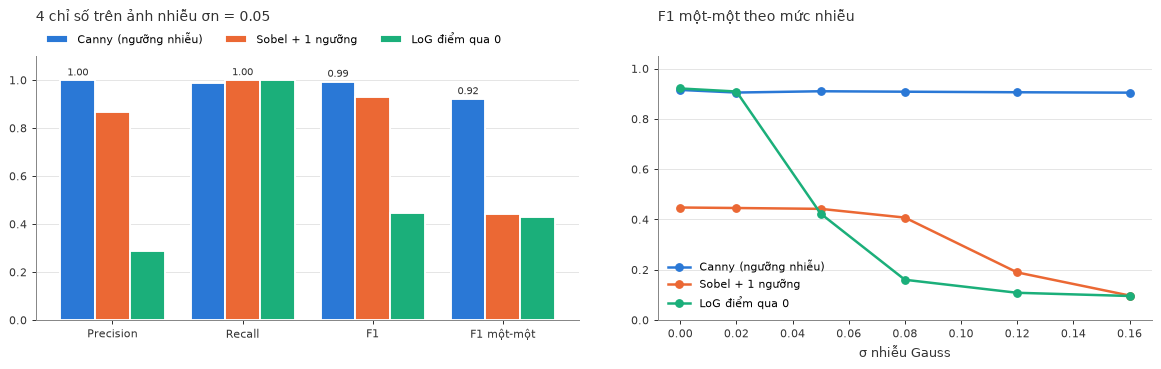

In [21]:
metric_keys = [("precision", "Precision"), ("recall", "Recall"), ("f1", "F1"), ("f1_1to1", "F1 một-một")]
algos = {"Canny (ngưỡng nhiễu)": lambda im: canny(im, 2.0, threshold_strategy="noise").edges,
         "Sobel + 1 ngưỡng": lambda im: registry.run("sobel_threshold_manual", im, threshold=0.3, sigma=1.0),
         "LoG điểm qua 0": lambda im: registry.run("log_manual", im, sigma=2.0)}
ms_base = {k: edge_metrics(v, GT) for k, v in base.items()}

noise_levels = [0.0, 0.02, 0.05, 0.08, 0.12, 0.16]
sweep = {a: [] for a in algos}
for nl in noise_levels:
    im = syn.degrade(scene["image"], np.random.default_rng(3), noise_sigma=nl)
    for a, fn in algos.items():
        sweep[a].append(edge_metrics(fn(im), GT)["f1_1to1"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.1, 1]))
grouped_bars(ax[0], [lab for _, lab in metric_keys], list(algos),
             [[m[k] for m in ms_base.values()] for k, _ in metric_keys])
ax[0].set_ylim(0, 1.1); style(ax[0], "4 chỉ số trên ảnh nhiễu σn = 0.05")
for j, (a, ys) in enumerate(sweep.items()):
    ax[1].plot(noise_levels, ys, "o-", color=PAL[j], lw=2, ms=6, label=a)
ax[1].set_ylim(0, 1.05)
style(ax[1], "F1 một-một theo mức nhiễu", xlabel="σ nhiễu Gauss")
ax[1].legend(frameon=False, fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

**Nhận xét 5.1:**
- **Sobel + 1 ngưỡng** có Recall cao nhưng cạnh dày, nên F1 một-một chỉ ≈ 0.45 ngay cả khi ít nhiễu, và tụt về ≈ 0.1
  khi nhiễu mạnh (một ngưỡng không phân biệt được cạnh với nhiễu).
- **LoG** tốt ngang Canny khi ảnh sạch (≈ 0.92) nhưng rất nhạy nhiễu: đạo hàm bậc hai khuếch đại nhiễu, sinh nhiều điểm
  qua 0 giả (Precision chỉ ≈ 0.29 ở σn = 0.05).
- **Canny** giữ F1 một-một ≈ 0.91 trên **mọi** mức nhiễu nhờ đủ 3 thứ: làm trơn, NMS (cạnh mảnh) và ngưỡng kép theo nhiễu.
  Thực nghiệm X4 lặp lại trên nhiều ảnh: Canny 0.92, LoG 0.54–0.92, Sobel 0.66–0.69.

### 5.2. Ảnh màu đẳng sáng: chuyển xám làm mất cạnh
Hình và nền khác màu nhưng **cùng độ sáng** Y. Chuyển sang ảnh xám thì cạnh biến mất hoàn toàn; Canny màu
(gradient Di Zenzo trên tensor cấu trúc) vẫn thấy.

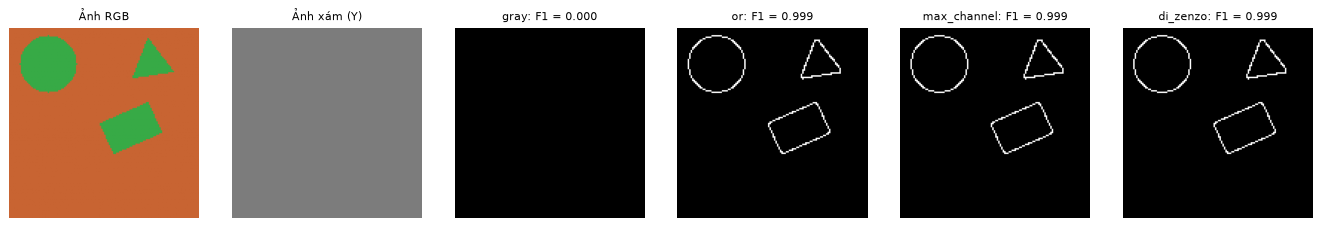

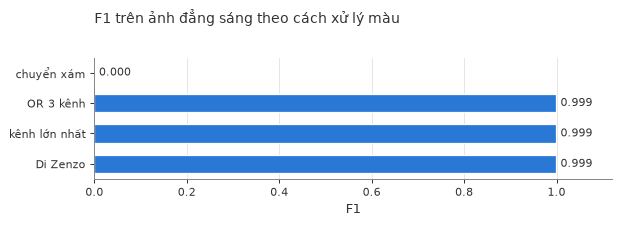

In [22]:
iso = syn.isoluminant_scene(128)
gray_y = cv2.cvtColor((iso["image"] * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
res_c = {m: canny_color(iso["image"], m, 1.0).edges for m in ["gray", "or", "max_channel", "di_zenzo"]}
show([iso["image"], np.stack([gray_y] * 3, -1)] + list(res_c.values()),   # xám vẽ dạng RGB để không bị co giãn độ sáng
     ["Ảnh RGB", "Ảnh xám (Y)"] + [f"{m}: F1 = {f1(e, iso['edges']):.3f}" for m, e in res_c.items()], cols=6, size=2.5)

fig, ax = plt.subplots(figsize=(7, 2.6))
labels_c = {"gray": "chuyển xám", "or": "OR 3 kênh", "max_channel": "kênh lớn nhất", "di_zenzo": "Di Zenzo"}
vals = [f1(e, iso["edges"]) for e in res_c.values()]
ax.barh(list(labels_c.values()), vals, color=PAL[0], edgecolor="white", height=0.6)
for y, v in enumerate(vals):
    ax.text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.invert_yaxis(); ax.set_xlim(0, 1.12)
style(ax, "F1 trên ảnh đẳng sáng theo cách xử lý màu", xlabel="F1", grid_axis="x"); ax.title.set_position((0, 1))
plt.tight_layout(); plt.show()

### 5.3. Video: làm trơn theo thời gian
Cảnh tĩnh, mỗi khung có nhiễu độc lập (σn = 0.08). Làm trơn Gauss **dọc trục thời gian** trước khi chạy Canny
giúp trung bình hóa nhiễu giữa các khung.

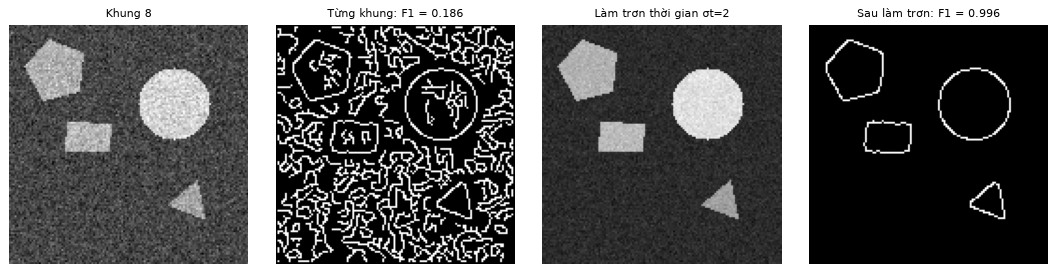

F1 trung bình 16 khung: từng khung = 0.189 (±0.006), làm trơn thời gian = 0.933 (±0.163)


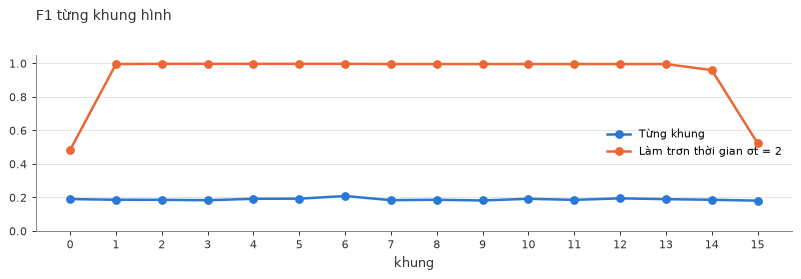

In [23]:
frames = syn.moving_video(n_frames=16, size=128, noise_sigma=0.08, speed=0.0, rng=np.random.default_rng(7))
stack = np.stack([fr["image"] for fr in frames])
gt_v = frames[0]["edges"]
smooth = gaussian_filter1d(stack, sigma=2.0, axis=0, mode="nearest")
t = 8
e_raw = canny(stack[t], 1.5, 0.04, 0.1).edges
e_tmp = canny(smooth[t], 1.5, 0.04, 0.1).edges
f_raw = [f1(canny(s, 1.5, 0.04, 0.1).edges, gt_v) for s in stack]
f_tmp = [f1(canny(s, 1.5, 0.04, 0.1).edges, gt_v) for s in smooth]
show([stack[t], e_raw, smooth[t], e_tmp],
     [f"Khung {t}", f"Từng khung: F1 = {f_raw[t]:.3f}", "Làm trơn thời gian σt=2", f"Sau làm trơn: F1 = {f_tmp[t]:.3f}"])
print(f"F1 trung bình 16 khung: từng khung = {np.mean(f_raw):.3f} (±{np.std(f_raw):.3f}), "
      f"làm trơn thời gian = {np.mean(f_tmp):.3f} (±{np.std(f_tmp):.3f})")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(range(len(f_raw)), f_raw, "o-", color=PAL[0], lw=2, ms=6, label="Từng khung")
ax.plot(range(len(f_tmp)), f_tmp, "o-", color=PAL[1], lw=2, ms=6, label="Làm trơn thời gian σt = 2")
ax.set_ylim(0, 1.05); ax.set_xticks(range(len(f_raw)))
style(ax, "F1 từng khung hình", xlabel="khung")
ax.legend(frameon=False, fontsize=9, loc="center right")
plt.tight_layout(); plt.show()

Làm trơn theo thời gian đưa F1 từ ≈ 0.19 lên ≈ 1.0 ở các khung giữa. Khung **đầu và cuối** (0, 15) chỉ đạt ≈ 0.5
vì chỉ có hàng xóm ở một phía để trung bình, nên độ lệch chuẩn lớn.
Lưu ý: cách này giả định cảnh tĩnh. Khi vật chuyển động, làm trơn thời gian gây nhòe cạnh (thực nghiệm X8b).

### 5.4. Tốc độ: tự cài so với thư viện

In [24]:
def timeit(fn, n=5):
    fn(); ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return np.median(ts) * 1000

big = data.camera()   # 512 × 512
rows = {
    "Tự cài, hồ sơ skimage (BFS)": lambda: canny(big, 1.5, profile=SKIMAGE),
    "Tự cài, hysteresis label": lambda: registry.run("canny_manual_fast", big, sigma=1.5, profile="skimage"),
    "skimage.feature.canny": lambda: feature.canny(big, sigma=1.5),
    "Tự cài, hồ sơ OpenCV": lambda: canny(big, None, 100, 200, profile=OPENCV),
    "cv2.Canny": lambda: cv2.Canny(big, 100, 200),
}
times = {k: timeit(fn) for k, fn in rows.items()}
for k, v in times.items():
    print(f"{k:32s} {v:8.2f} ms")

Tự cài, hồ sơ skimage (BFS)         37.93 ms
Tự cài, hysteresis label            24.28 ms
skimage.feature.canny               14.15 ms
Tự cài, hồ sơ OpenCV                39.03 ms
cv2.Canny                            0.49 ms


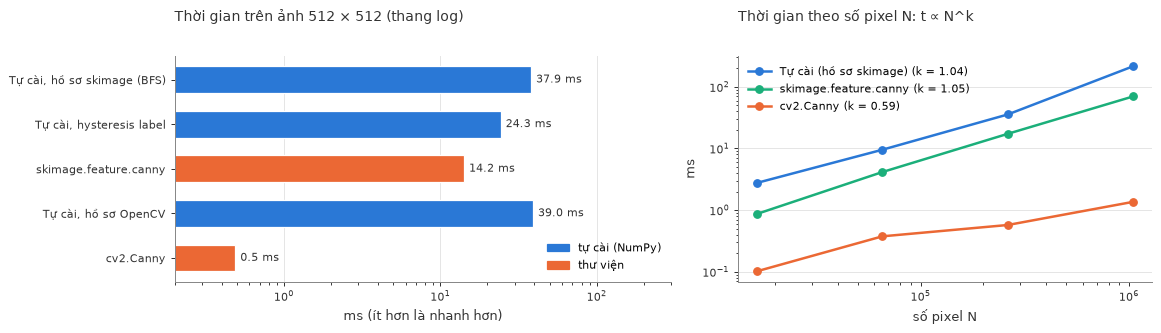

In [25]:
# Trái: thời gian trên ảnh 512². Phải: thời gian theo kích thước ảnh (log–log), độ dốc ≈ 1 nghĩa là O(N)
sizes = [128, 256, 512, 1024]
scal = {"Tự cài (hồ sơ skimage)": lambda im: canny(im, 1.5, profile=SKIMAGE),
        "skimage.feature.canny": lambda im: feature.canny(im, sigma=1.5),
        "cv2.Canny": lambda im: cv2.Canny(im, 100, 200)}
imgs = {s: cv2.resize(big, (s, s), interpolation=cv2.INTER_LINEAR) for s in sizes}   # đổi cỡ trước, không tính vào thời gian
t_size = {k: [timeit(lambda: fn(imgs[s]), n=3) for s in sizes] for k, fn in scal.items()}

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
names = list(times)
cols = [PAL[0] if n.startswith("Tự cài") else PAL[1] for n in names]
ax[0].barh(names, list(times.values()), color=cols, edgecolor="white", height=0.6)
for y, v in enumerate(times.values()):
    ax[0].text(v * 1.08, y, f"{v:.1f} ms", va="center", fontsize=9, color=INK)
ax[0].set_xscale("log"); ax[0].set_xlim(0.2, 300); ax[0].invert_yaxis()
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=PAL[0], label="tự cài (NumPy)"), Patch(color=PAL[1], label="thư viện")],
             frameon=False, fontsize=9, loc="lower right")
style(ax[0], "Thời gian trên ảnh 512 × 512 (thang log)", xlabel="ms (ít hơn là nhanh hơn)", grid_axis="x")

for j, (k, ys) in enumerate(t_size.items()):
    kk = np.polyfit(np.log([s * s for s in sizes]), np.log(ys), 1)[0]
    ax[1].loglog([s * s for s in sizes], ys, "o-", color=[PAL[0], PAL[2], PAL[1]][j], lw=2, ms=6,
                 label=f"{k} (k = {kk:.2f})")
style(ax[1], "Thời gian theo số pixel N: t ∝ N^k", xlabel="số pixel N", ylabel="ms")
ax[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

`cv2.Canny` nhanh hơn bản tự cài khoảng 70 lần (C++ tối ưu SIMD, đa luồng). Ở biểu đồ phải, `cv2.Canny` ra k < 1 vì ảnh
nhỏ thì thời gian chủ yếu là chi phí cố định, cộng thêm đa luồng; thực nghiệm X9 tắt đa luồng để so cho công bằng.
Mọi bước của Canny là O(N) theo số pixel (đo trên 128² … 1024² ra t ∝ N^k với k ≈ 1, thực nghiệm X9).
Bản tự cài chậm hơn thư viện vì NumPy thuần, nhưng cho ra **cùng kết quả** và cho xem được mọi bước trung gian.

## Tổng kết

| | Kết quả |
|---|---|
| Đúng | Canny tự cài lệch **0 pixel** so với `cv2.Canny` và `skimage.feature.canny` |
| Tham số | σ lớn làm giảm đỉnh gradient (∝ 1/σ): giữ ngưỡng cố định thì mất cạnh; ngưỡng nên chọn theo nhiễu |
| Ảnh khó | Tham số mặc định hỏng với nhiễu; ngưỡng theo nhiễu (+ trung vị cho muối tiêu) khôi phục F1 |
| Ứng dụng | Canny + hình thái học + xấp xỉ đa giác: phân đoạn và nhận dạng hình |
| Mở rộng | Ảnh màu đẳng sáng cần Canny màu; video tĩnh hưởng lợi từ làm trơn thời gian |

Số liệu đầy đủ (10 thực nghiệm, nhiều seed): `results/` và [docs/experiments/README.md](docs/experiments/README.md).
Chạy lại một thực nghiệm: `python -m cannylab run Lab3/canny_project/configs/x3_anh_kho.toml`.